# 3. Validation and calibration

Scores of the five hypothesis engine on unseen practice fields, read from data/validation.json, then a fresh check on new fields that neither training nor testing used.

In [1]:
import os, sys, json, math, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "backend"))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
for f in os.listdir(os.path.join(ROOT, "scripts", "fonts")):
    font_manager.fontManager.addfont(os.path.join(ROOT, "scripts", "fonts", f))
plt.rcParams.update({"font.family": "EB Garamond", "font.size": 12, "figure.facecolor": "#f5f0e6", "axes.facecolor": "#fbf8f2"})
import core, sky, pipeline as P
import engine
V = json.load(open(os.path.join(ROOT, 'data', 'validation.json')))

In [2]:
print("test fields", V["test_fields"], "candidates", V["test_candidates"])
print("accuracy when deciding %.3f, unknown %.3f, Brier %.3f, ECE %.4f" % (V["unknown"]["accuracy_when_decided"], V["unknown"]["fraction"], V["brier"], V["ece"]))
for k, a in V["per_class"].items():
    print(k.ljust(10), "precision %.2f recall %.2f n %d" % (a["precision"], a["recall"], a["n"]))

test fields 109 candidates 512
accuracy when deciding 0.988, unknown 0.018, Brier 0.021, ECE 0.0066
moving     precision 1.00 recall 0.99 n 125
variable   precision 1.00 recall 0.97 n 122
transient  precision 1.00 recall 1.00 n 127
artefact   precision 0.99 recall 0.99 n 117
null       precision 0.77 recall 0.95 n 21


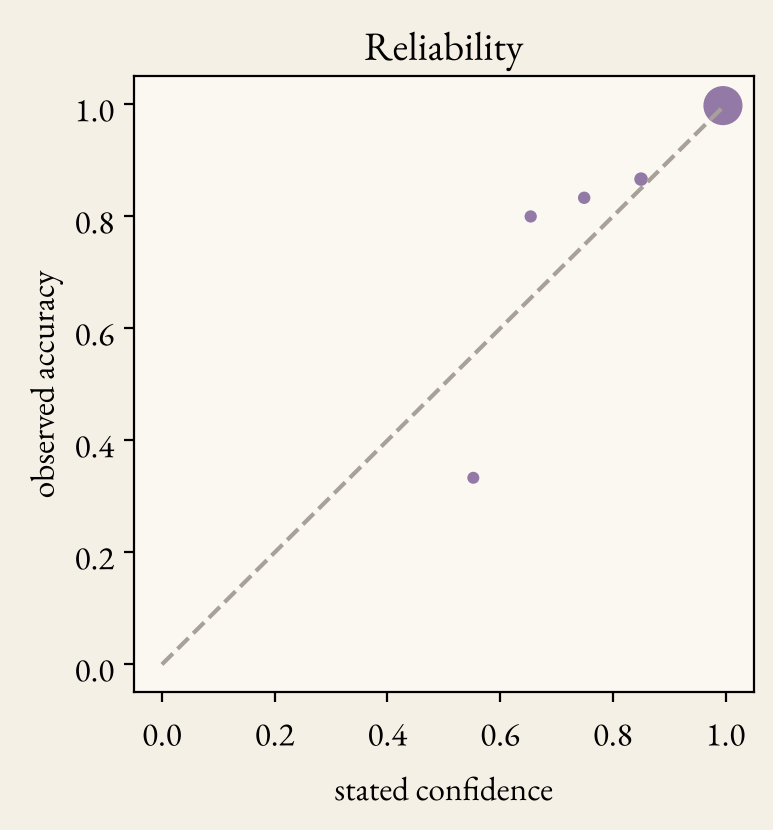

In [3]:
r = V["reliability"]
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 1], [0, 1], "--", color="#a7a19a")
ax.scatter([x["confidence"] for x in r], [x["accuracy"] for x in r], s=[10 + x["n"] / 3 for x in r], color="#937aa6")
ax.set_xlabel("stated confidence"); ax.set_ylabel("observed accuracy"); ax.set_title("Reliability")
plt.show()

In [4]:
for k, a in sorted(V["agreement_by_count"].items()):
    print(k, "methods: real sky change in %.0f percent of %d (%.0f to %.0f)" % (100 * a["sky_fraction"], a["n"], 100 * a["lo"], 100 * a["hi"]))
print("A only:", V["agreement_patterns"].get("A"))

1 methods: real sky change in 34 percent of 134 (26 to 42)
2 methods: real sky change in 77 percent of 103 (68 to 84)
3 methods: real sky change in 91 percent of 275 (87 to 94)
A only: {'n': 79, 'sky': 4, 'artefact': 68, 'null': 7, 'sky_fraction': 0.05063291139240506, 'lo': 0.01986372131473304, 'hi': 0.12307895482865383}


## A fresh check on new fields

Six fields with seeds that no script used before. The engine is frozen.

In [5]:
ok = tot = 0
for seed in range(90000, 90006):
    rng = np.random.default_rng(seed)
    spec = sky.make_spec(seed, center=(float(rng.uniform(0, 360)), float(rng.uniform(-60, 60))), events="random")
    E, truth, cat = sky.render(spec)
    core.prepare(E)
    S = P.run(E, cat, center=spec["center"])
    P.match_truth(S, truth)
    for c in S["cands"]:
        p = engine.posterior(c["f"])
        v = "null" if p["unknown"] else p["verdict"]
        tot += 1
        ok += v == c["truth"]
print(f"{ok} of {tot} candidates labelled as planted")

31 of 32 candidates labelled as planted


## Negative controls

In [6]:
print(json.dumps(V["controls"], indent=1)[:900])

{
 "null_fields": 40,
 "null_candidates_mean": 0.375,
 "null_candidates_max": 2,
 "null_candidates_per_deg2": 53.51726092712211,
 "null_patterns": {
  "A": 1,
  "P": 14
 },
 "static_stars": 840,
 "static_called_moving": 0,
 "static_false_motion_rate": 0.0,
 "static_lo_hi": [
  0.0,
  0.004552513173088408
 ],
 "astrometric_floor_px": 0.020486619903342954,
 "photometric_floor": {
  "1": 0.016912874107729882,
  "2": 0.014480840882956132,
  "3": 0.014393990534455996,
  "4": 0.016370156305006812,
  "5": 0.012568155926583295,
  "6": 0.013052593027477317
 }
}
